<a href="https://colab.research.google.com/github/2023A51012/labexm-pds/blob/main/Python_lab_test_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install kagglehub pyyaml scikit-learn seaborn

In [ ]:
import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "rupankarmajumdar/crop-pests-dataset"
)

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)
print("Files in dataset:", os.listdir(dataset_path))

100%|██████████| 537M/537M [00:06<00:00, 89.5MB/s]

Extracting files...


Dataset downloaded successfully!
Dataset location: /root/.cache/kagglehub/datasets/rupankarmajumdar/crop-pests-dataset/versions/2
Files in dataset: ['train', 'valid', 'data.yaml', 'test']


In [ ]:
import yaml
from pathlib import Path

yaml_files = list(Path(dataset_path).rglob("data.yaml"))

if not yaml_files:
    raise FileNotFoundError("data.yaml was not found.")

yaml_path = yaml_files[0]

with open(yaml_path, "r") as file:
    config = yaml.safe_load(file)

names = config["names"]

if isinstance(names, dict):
    class_names = [names[k] for k in sorted(names, key=lambda x: int(x))]
else:
    class_names = list(names)

print("Dataset:", "Crop Pests Dataset")
print("Number of classes:", len(class_names))
print("Classes:")

for name in class_names:
    print("-", name)

Dataset: Crop Pests Dataset
Number of classes: 12
Classes:
- Ants
- Bees
- Beetles
- Caterpillars
- Earthworms
- Earwigs
- Grasshoppers
- Moths
- Slugs
- Snails
- Wasps
- Weevils


In [ ]:
import hashlib
import pandas as pd
from collections import Counter
from PIL import Image

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
records = []
seen_hashes = set()
skipped = 0

image_paths = [
    p for p in Path(dataset_path).rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
    and "images" in p.parts
]

for img_path in image_paths:
    parts = list(img_path.parts)
    image_folder_index = len(parts) - 1 - parts[::-1].index("images")
    label_path = Path(
        *parts[:image_folder_index],
        "labels",
        img_path.stem + ".txt"
    )

    if not label_path.exists():
        skipped += 1
        continue

    with open(label_path, "r") as file:
        lines = [line.strip() for line in file if line.strip()]

    class_ids = []
    for line in lines:
        try:
            class_id = int(line.split()[0])
            if 0 <= class_id < len(class_names):
                class_ids.append(class_id)
        except (ValueError, IndexError):
            continue

    if not class_ids:
        skipped += 1
        continue

    try:
        with open(img_path, "rb") as file:
            image_hash = hashlib.sha256(file.read()).hexdigest()

        if image_hash in seen_hashes:
            continue
        seen_hashes.add(image_hash)

        majority_class = Counter(class_ids).most_common(1)[0][0]

        records.append({
            "filepath": str(img_path),
            "label": class_names[majority_class]
        })
    except Exception:
        skipped += 1

df = pd.DataFrame(records)

if df.empty:
    raise ValueError(
        "No labeled images found. Check the dataset folder structure."
    )

print("Unique labeled images:", len(df))
print("Number of classes:", df["label"].nunique())
print("Skipped images:", skipped)
print("\nClass distribution:")
print(df["label"].value_counts().sort_index())

Unique labeled images: 13137
Number of classes: 12
Skipped images: 3

Class distribution:
label
Ants            1182
Bees            1237
Beetles          986
Caterpillars    1032
Earthworms       792
Earwigs         1092
Grasshoppers    1179
Moths           1205
Slugs            919
Snails          1221
Wasps           1170
Weevils         1122
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Total images:", len(train_df) + len(val_df) + len(test_df))

Training images: 9195
Validation images: 1971
Testing images: 1971
Total images: 13137


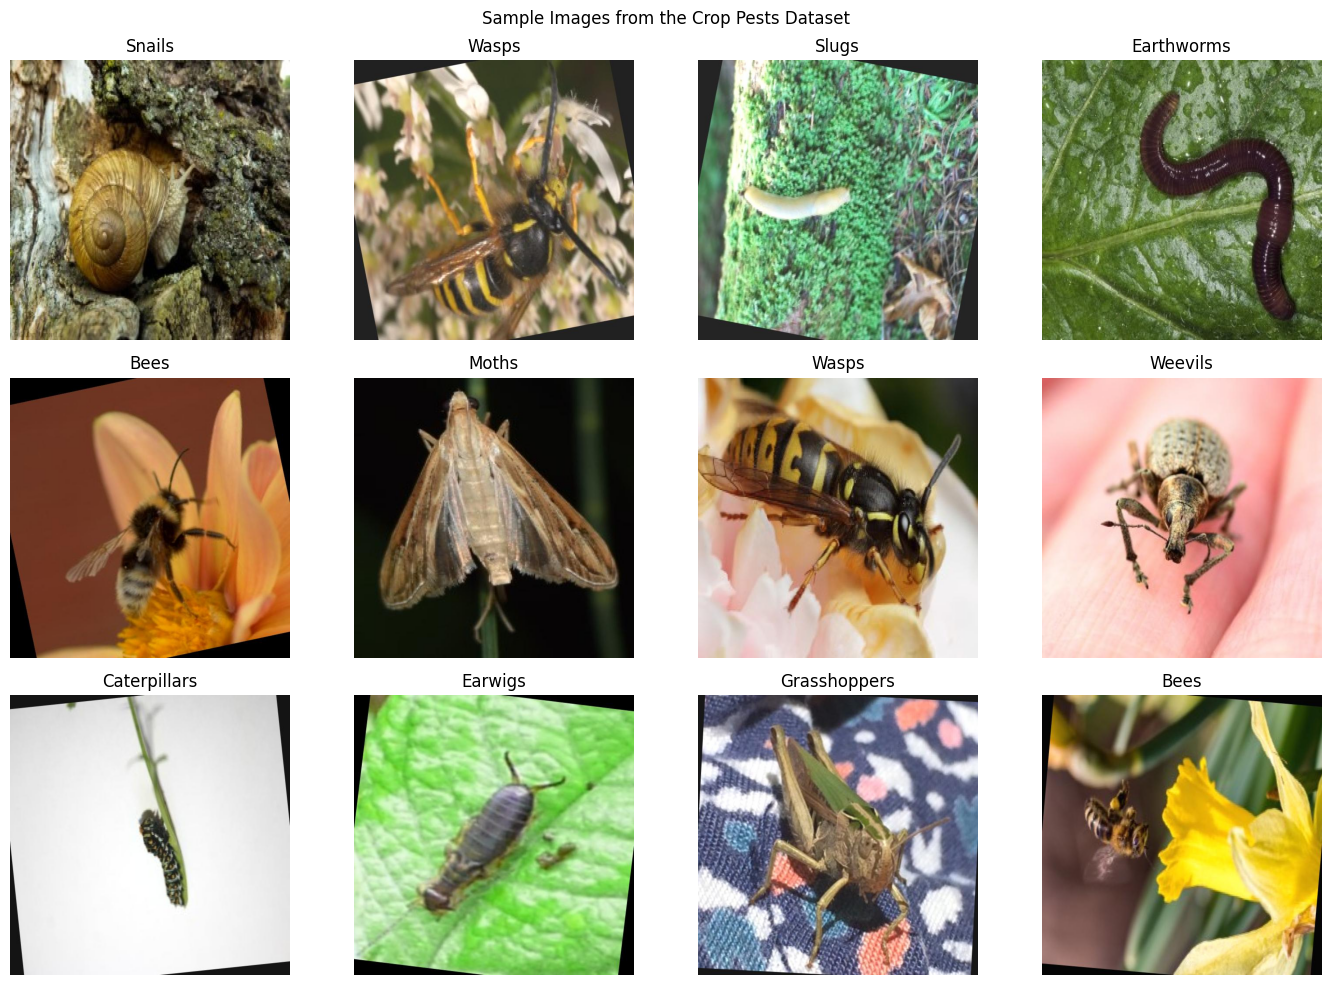

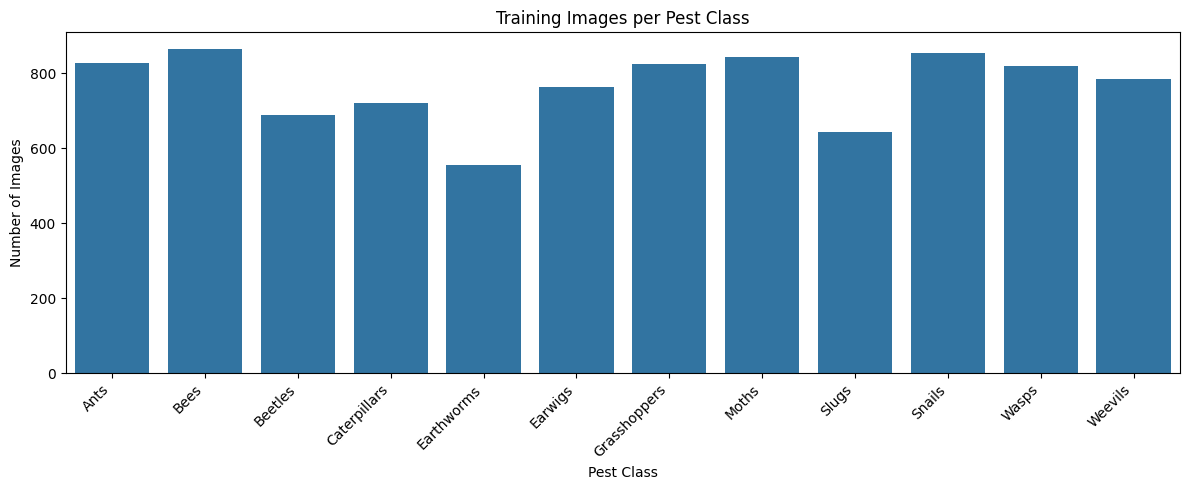

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import random
from PIL import Image

# Display sample pest images
samples = train_df.sample(
    n=min(12, len(train_df)),
    random_state=42
)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for ax, (_, row) in zip(axes, samples.iterrows()):
    img = Image.open(row["filepath"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(row["label"])
    ax.axis("off")

for ax in axes[len(samples):]:
    ax.axis("off")

plt.suptitle("Sample Images from the Crop Pests Dataset")
plt.tight_layout()
plt.show()

# Class distribution graph
plt.figure(figsize=(12, 5))
sns.countplot(
    data=train_df,
    x="label",
    order=class_names
)
plt.title("Training Images per Pest Class")
plt.xlabel("Pest Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time, random

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50, MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ReduceLROnPlateau
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix
)

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10
NUM_CLASSES = len(class_names)

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Number of classes:", NUM_CLASSES)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs per model:", EPOCHS)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
Number of classes: 12
Image size: (224, 224)
Batch size: 32
Epochs per model: 10
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

def make_generators(preprocess_function):
    train_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_function,
        rotation_range=15,
        width_shift_range=0.1,
        height_shift_range=0.1,
        zoom_range=0.1,
        horizontal_flip=True
    )

    eval_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_function
    )

    train_gen = train_datagen.flow_from_dataframe(
        train_df,
        x_col="filepath",
        y_col="label",
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        classes=class_names,
        class_mode="categorical",
        shuffle=True,
        seed=SEED
    )

    val_gen = eval_datagen.flow_from_dataframe(
        val_df,
        x_col="filepath",
        y_col="label",
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        classes=class_names,
        class_mode="categorical",
        shuffle=False
    )

    test_gen = eval_datagen.flow_from_dataframe(
        test_df,
        x_col="filepath",
        y_col="label",
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        classes=class_names,
        class_mode="categorical",
        shuffle=False
    )

    return train_gen, val_gen, test_gen

print("Generator preparation function created.")


Generator preparation function created.


In [ ]:

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import random

from tensorflow.keras.applications import ResNet50, MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ReduceLROnPlateau

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix
)

print("TensorFlow imported successfully!")
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Dataset variables available:", all(
    name in globals()
    for name in ["train_df", "val_df", "test_df", "class_names"]
))


TensorFlow imported successfully!
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Dataset variables available: False


In [ ]:

from pathlib import Path
import yaml

# Find the dataset in the KaggleHub cache
cache_path = Path(
    "/root/.cache/kagglehub/datasets/rupankarmajumdar/crop-pests-dataset/versions"
)

possible_paths = list(cache_path.glob("*")) if cache_path.exists() else []

# Check other common locations
kaggle_path = Path(
    "/kaggle/input/datasets/rupankarmajumdar/crop-pests-dataset"
)
if kaggle_path.exists():
    possible_paths.append(kaggle_path)

dataset_root = next(
    (p for p in possible_paths if p.exists() and list(p.rglob("data.yaml"))),
    None
)

# Download only if the dataset was not found
if dataset_root is None:
    import kagglehub
    dataset_path = kagglehub.dataset_download(
        "rupankarmajumdar/crop-pests-dataset"
    )
    dataset_root = Path(dataset_path)
else:
    dataset_path = str(dataset_root)

yaml_files = list(dataset_root.rglob("data.yaml"))

if not yaml_files:
    raise FileNotFoundError("Could not find data.yaml in the dataset.")

with open(yaml_files[0], "r") as f:
    config = yaml.safe_load(f)

names = config["names"]
class_names = (
    [names[i] for i in range(len(names))]
    if isinstance(names, dict)
    else list(names)
)

print("Dataset location:", dataset_path)
print("Configuration found: True")
print("Number of classes:", len(class_names))
print("Classes:", class_names)


100%|██████████| 537M/537M [00:40<00:00, 13.9MB/s]

Extracting files...


Dataset location: /root/.cache/kagglehub/datasets/rupankarmajumdar/crop-pests-dataset/versions/2
Configuration found: True
Number of classes: 12
Classes: ['Ants', 'Bees', 'Beetles', 'Caterpillars', 'Earthworms', 'Earwigs', 'Grasshoppers', 'Moths', 'Slugs', 'Snails', 'Wasps', 'Weevils']


In [ ]:

from pathlib import Path

image_dirs = [
    p for p in dataset_root.rglob("*")
    if p.is_dir() and p.name.lower() == "images"
]

print("Image folders found:", len(image_dirs))

for folder in image_dirs:
    image_count = sum(
        1 for p in folder.rglob("*")
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    )
    print("\nFolder:", folder)
    print("Images:", image_count)
    print("Matching labels folder:", folder.parent / "labels")
    print("Labels folder exists:", (folder.parent / "labels").exists())


Image folders found: 3

Folder: /root/.cache/kagglehub/datasets/rupankarmajumdar/crop-pests-dataset/versions/2/train/images
Images: 11502
Matching labels folder: /root/.cache/kagglehub/datasets/rupankarmajumdar/crop-pests-dataset/versions/2/train/labels
Labels folder exists: True

Folder: /root/.cache/kagglehub/datasets/rupankarmajumdar/crop-pests-dataset/versions/2/valid/images
Images: 1095
Matching labels folder: /root/.cache/kagglehub/datasets/rupankarmajumdar/crop-pests-dataset/versions/2/valid/labels
Labels folder exists: True

Folder: /root/.cache/kagglehub/datasets/rupankarmajumdar/crop-pests-dataset/versions/2/test/images
Images: 546
Matching labels folder: /root/.cache/kagglehub/datasets/rupankarmajumdar/crop-pests-dataset/versions/2/test/labels
Labels folder exists: True


In [ ]:

from pathlib import Path
from collections import Counter
import pandas as pd

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def build_dataframe(split_name):
    image_folder = dataset_root / split_name / "images"
    label_folder = dataset_root / split_name / "labels"
    rows = []
    skipped = 0

    for img_path in image_folder.rglob("*"):
        if img_path.suffix.lower() not in IMAGE_EXTS:
            continue

        label_path = label_folder / (img_path.stem + ".txt")

        if not label_path.exists():
            skipped += 1
            continue

        class_ids = []
        with open(label_path, "r") as f:
            for line in f:
                parts = line.strip().split()
                if not parts:
                    continue
                try:
                    class_id = int(float(parts[0]))
                    if 0 <= class_id < len(class_names):
                        class_ids.append(class_id)
                except ValueError:
                    continue

        if not class_ids:
            skipped += 1
            continue

        majority_id = Counter(class_ids).most_common(1)[0][0]

        rows.append({
            "filename": str(img_path),
            "label": class_names[majority_id]
        })

    df = pd.DataFrame(rows)
    print(
        f"{split_name}: {len(df)} usable images; "
        f"{skipped} skipped"
    )
    return df

train_df = build_dataframe("train")
val_df = build_dataframe("valid")
test_df = build_dataframe("test")

print("\nFinal dataset sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nTraining class distribution:")
print(train_df["label"].value_counts().sort_index())


train: 11499 usable images; 3 skipped
valid: 1095 usable images; 0 skipped
test: 546 usable images; 0 skipped

Final dataset sizes:
Train: 11499
Validation: 1095
Test: 546

Training class distribution:
label
Ants            1032
Bees            1098
Beetles          857
Caterpillars     909
Earthworms       714
Earwigs          942
Grasshoppers    1044
Moths           1059
Slugs            797
Snails          1079
Wasps           1008
Weevils          960
Name: count, dtype: int64


In [ ]:

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import random

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50, MobileNetV2
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix
)

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10
NUM_CLASSES = len(class_names)

tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

def make_generators(preprocess_function):
    train_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_function,
        rotation_range=15,
        width_shift_range=0.1,
        height_shift_range=0.1,
        horizontal_flip=True,
        zoom_range=0.1
    )

    eval_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_function
    )

    train_gen = train_datagen.flow_from_dataframe(
        dataframe=train_df, x_col="filename", y_col="label",
        classes=class_names, target_size=IMG_SIZE,
        batch_size=BATCH_SIZE, class_mode="categorical",
        shuffle=True, seed=SEED
    )

    val_gen = eval_datagen.flow_from_dataframe(
        dataframe=val_df, x_col="filename", y_col="label",
        classes=class_names, target_size=IMG_SIZE,
        batch_size=BATCH_SIZE, class_mode="categorical",
        shuffle=False
    )

    test_gen = eval_datagen.flow_from_dataframe(
        dataframe=test_df, x_col="filename", y_col="label",
        classes=class_names, target_size=IMG_SIZE,
        batch_size=BATCH_SIZE, class_mode="categorical",
        shuffle=False
    )

    return train_gen, val_gen, test_gen

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Number of classes:", NUM_CLASSES)


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Number of classes: 12


In [ ]:

resnet_train, resnet_val, resnet_test = make_generators(
    resnet_preprocess
)

print("ResNet50 generators created successfully.")
print("Training images:", resnet_train.samples)
print("Validation images:", resnet_val.samples)
print("Testing images:", resnet_test.samples)


Found 11499 validated image filenames belonging to 12 classes.
Found 1095 validated image filenames belonging to 12 classes.
Found 546 validated image filenames belonging to 12 classes.
ResNet50 generators created successfully.
Training images: 11499
Validation images: 1095
Testing images: 546


In [ ]:

base_resnet = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_resnet.trainable = False

x = GlobalAveragePooling2D()(base_resnet.output)
x = Dropout(0.3)(x)
output = Dense(NUM_CLASSES, activation="softmax")(x)

resnet_model = Model(inputs=base_resnet.input, outputs=output)

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

lr_callback = ReduceLROnPlateau(
    monitor="val_loss", factor=0.2, patience=2,
    min_lr=1e-6, verbose=1
)

start_time = time.time()

resnet_history = resnet_model.fit(
    resnet_train,
    validation_data=resnet_val,
    epochs=EPOCHS,
    callbacks=[lr_callback],
    verbose=1
)

resnet_train_time = time.time() - start_time

print(f"\nResNet50 training time: {resnet_train_time / 60:.2f} minutes")
print("ResNet50 parameters:", f"{resnet_model.count_params():,}")


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
Epoch 1/10
360/360 ━━━━━━━━━━━━━━━━━━━━ 198s 514ms/step - accuracy: 0.7476 - loss: 0.8049 - val_accuracy: 0.8858 - val_loss: 0.4036 - learning_rate: 0.0010
Epoch 2/10
360/360 ━━━━━━━━━━━━━━━━━━━━ 172s 477ms/step - accuracy: 0.8611 - loss: 0.4369 - val_accuracy: 0.8895 - val_loss: 0.3685 - learning_rate: 0.0010
Epoch 3/10
360/360 ━━━━━━━━━━━━━━━━━━━━ 167s 462ms/step - accuracy: 0.8814 - loss: 0.3720 - val_accuracy: 0.8813 - val_loss: 0.3902 - learning_rate: 0.0010
Epoch 4/10
360/360 ━━━━━━━━━━━━━━━━━━━━ 0s 458ms/step - accuracy: 0.8940 - loss: 0.3352
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
360/360 ━━━━━━━━━━━━━━━━━━━━ 171s 474ms/step - accuracy: 0.8934 - loss: 0.3355 - val_accuracy: 0.8849 - val_loss: 0.3795 - learning_rate: 0.0010
Epoch 5/10
360/360 ━━━━━━━━━━━━━━━━━━━━ 177s 491ms/step - accuracy: 0.9091 - loss: 0.2823 - val_accuracy: 0.8886 - val_loss: 0.3595 - learning_rate: 2.0000e-04
Epoch 6/10


In [ ]:

# Create MobileNetV2 data generators
mobilenet_train, mobilenet_val, mobilenet_test = make_generators(
    mobilenet_preprocess
)

# Load pretrained MobileNetV2
base_mobile = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_mobile.trainable = False

x = GlobalAveragePooling2D()(base_mobile.output)
x = Dropout(0.3)(x)
output = Dense(NUM_CLASSES, activation="softmax")(x)

mobilenet_model = Model(
    inputs=base_mobile.input,
    outputs=output
)

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

start_time = time.time()

mobilenet_history = mobilenet_model.fit(
    mobilenet_train,
    validation_data=mobilenet_val,
    epochs=EPOCHS,
    callbacks=[lr_callback],
    verbose=1
)

mobilenet_train_time = time.time() - start_time

print(f"\nMobileNetV2 training time: {mobilenet_train_time / 60:.2f} minutes")
print("MobileNetV2 parameters:", f"{mobilenet_model.count_params():,}")


Found 11499 validated image filenames belonging to 12 classes.
Found 1095 validated image filenames belonging to 12 classes.
Found 546 validated image filenames belonging to 12 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/10
360/360 ━━━━━━━━━━━━━━━━━━━━ 180s 471ms/step - accuracy: 0.7401 - loss: 0.8293 - val_accuracy: 0.8749 - val_loss: 0.4243 - learning_rate: 0.0010
Epoch 2/10
360/360 ━━━━━━━━━━━━━━━━━━━━ 0s 440ms/step - accuracy: 0.8360 - loss: 0.5096
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
360/360 ━━━━━━━━━━━━━━━━━━━━ 163s 453ms/step - accuracy: 0.8441 - loss: 0.4914 - val_accuracy: 0.8785 - val_loss: 0.4030 - learning_rate: 0.0010
Epoch 3/10
360/360 ━━━━━━━━━━━━━━━━━━━━ 162s 450ms/step - accuracy: 0.8676 - loss: 0.4124 - val_accuracy: 0.8740 - val_loss: 0.3939 - learning_rate: 2.0000e-04
Epoch 4/10
360/360 ━━━━━━━━━━━━━━━━━━━━ 0s 441ms/step - accuracy: 0.8726 - loss: 0.3987
Epoch 4: ReduceLROnPlateau reducing learning rate t

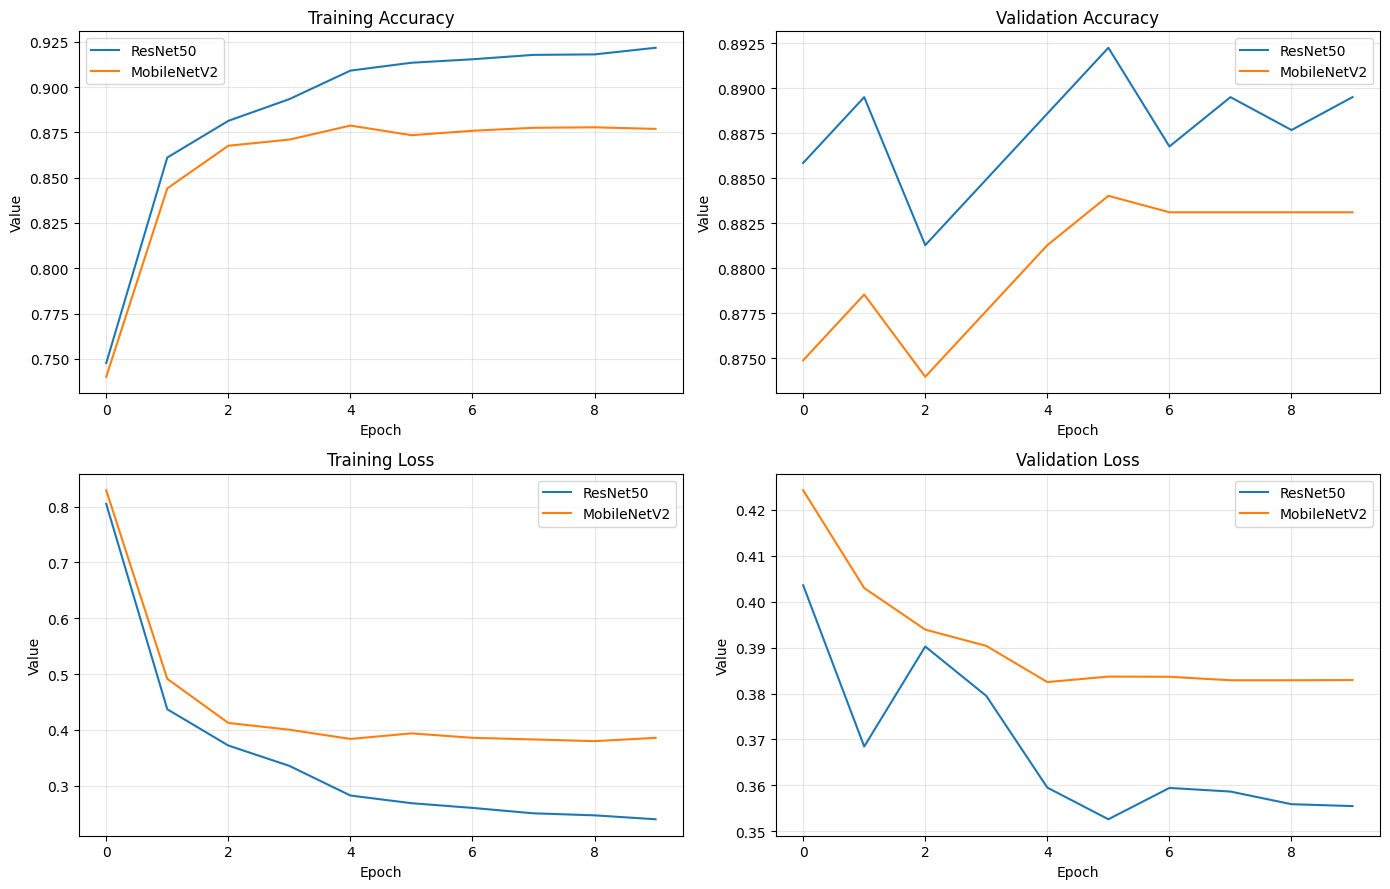

In [ ]:

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

histories = [
    (resnet_history, "ResNet50"),
    (mobilenet_history, "MobileNetV2")
]

for history, name in histories:
    axes[0, 0].plot(history.history["accuracy"], label=name)
    axes[0, 1].plot(history.history["val_accuracy"], label=name)
    axes[1, 0].plot(history.history["loss"], label=name)
    axes[1, 1].plot(history.history["val_loss"], label=name)

axes[0, 0].set_title("Training Accuracy")
axes[0, 1].set_title("Validation Accuracy")
axes[1, 0].set_title("Training Loss")
axes[1, 1].set_title("Validation Loss")

for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Value")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

def evaluate_model(model, test_gen, model_name):
    test_gen.reset()

    start = time.perf_counter()
    probabilities = model.predict(test_gen, verbose=1)
    inference_seconds = time.perf_counter() - start

    y_true = test_gen.classes
    y_pred = np.argmax(probabilities, axis=1)

    try:
        auc = roc_auc_score(
            y_true,
            probabilities,
            labels=np.arange(NUM_CLASSES),
            multi_class="ovr",
            average="macro"
        )
    except ValueError:
        auc = float("nan")

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "ROC-AUC": auc,
        "Parameters": model.count_params(),
        "Inference_seconds": inference_seconds,
        "Milliseconds_per_image": (
            inference_seconds / len(y_true) * 1000
        )
    }

    print(f"\n{model_name} TEST RESULTS")
    for key, value in results.items():
        if key == "Model":
            continue
        elif key == "Parameters":
            print(f"{key}: {value:,}")
        elif key == "Inference_seconds":
            print(f"{key}: {value:.2f}")
        elif key == "Milliseconds_per_image":
            print(f"{key}: {value:.2f} ms")
        else:
            print(f"{key}: {value:.4f}")

    print("\nClassification report:")
    print(classification_report(
        y_true, y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        zero_division=0
    ))

    return results, y_true, y_pred, probabilities

resnet_results, resnet_y_true, resnet_y_pred, resnet_probs = (
    evaluate_model(resnet_model, resnet_test, "ResNet50")
)

mobile_results, mobile_y_true, mobile_y_pred, mobile_probs = (
    evaluate_model(mobilenet_model, mobilenet_test, "MobileNetV2")
)


18/18 ━━━━━━━━━━━━━━━━━━━━ 14s 404ms/step

ResNet50 TEST RESULTS
Accuracy: 0.8919
Precision: 0.8882
Recall: 0.8929
F1-score: 0.8882
ROC-AUC: 0.9906
Parameters: 23,612,300
Inference_seconds: 14.44
Milliseconds_per_image: 26.45 ms

Classification report:
              precision    recall  f1-score   support

        Ants       0.91      0.96      0.94        54
        Bees       0.87      0.97      0.92        40
     Beetles       0.89      0.76      0.82        41
Caterpillars       0.83      0.74      0.78        46
  Earthworms       0.89      0.89      0.89        27
     Earwigs       0.89      0.71      0.79        59
Grasshoppers       0.79      0.87      0.82        38
       Moths       0.96      1.00      0.98        47
       Slugs       0.85      0.87      0.86        46
      Snails       0.93      0.98      0.96        44
       Wasps       0.90      1.00      0.95        46
     Weevils       0.95      0.97      0.96        58

    accuracy                           0.89

In [ ]:

results_df = pd.DataFrame([resnet_results, mobile_results])

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Inference_seconds": "{:.2f}",
        "Milliseconds_per_image": "{:.2f}"
    })
)


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Parameters,Inference_seconds,Milliseconds_per_image
0,ResNet50,0.8919,0.8882,0.8929,0.8882,0.9906,23612300,14.44,26.45
1,MobileNetV2,0.8681,0.8630,0.8609,0.8578,0.9888,2273356,9.70,17.77


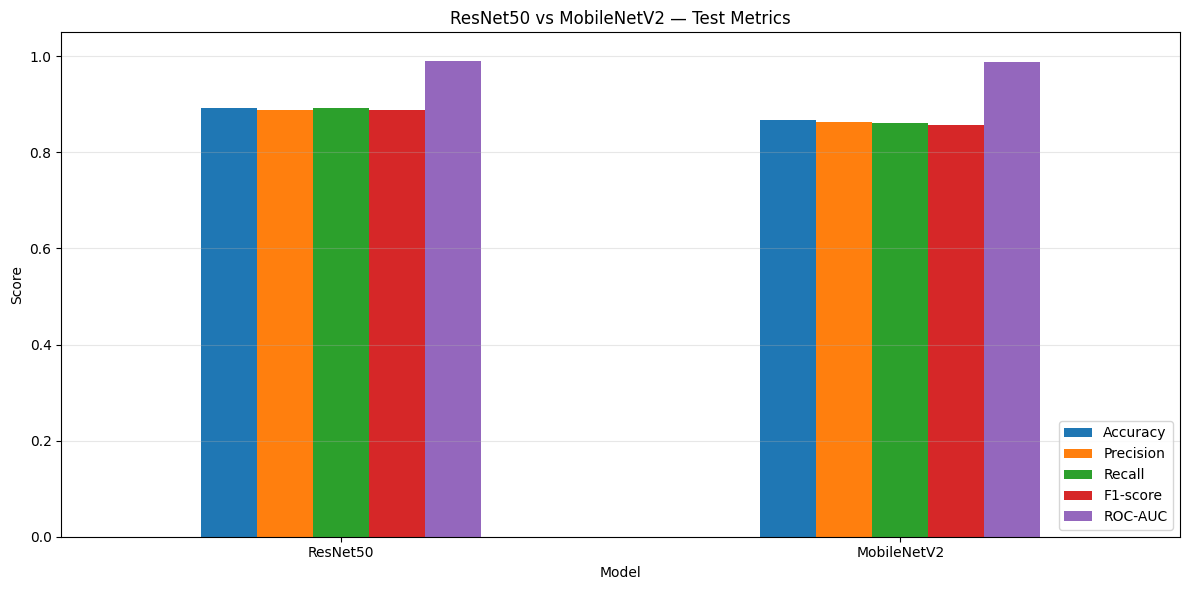

In [ ]:

metric_columns = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

results_df.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05)
)

plt.title("ResNet50 vs MobileNetV2 — Test Metrics")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


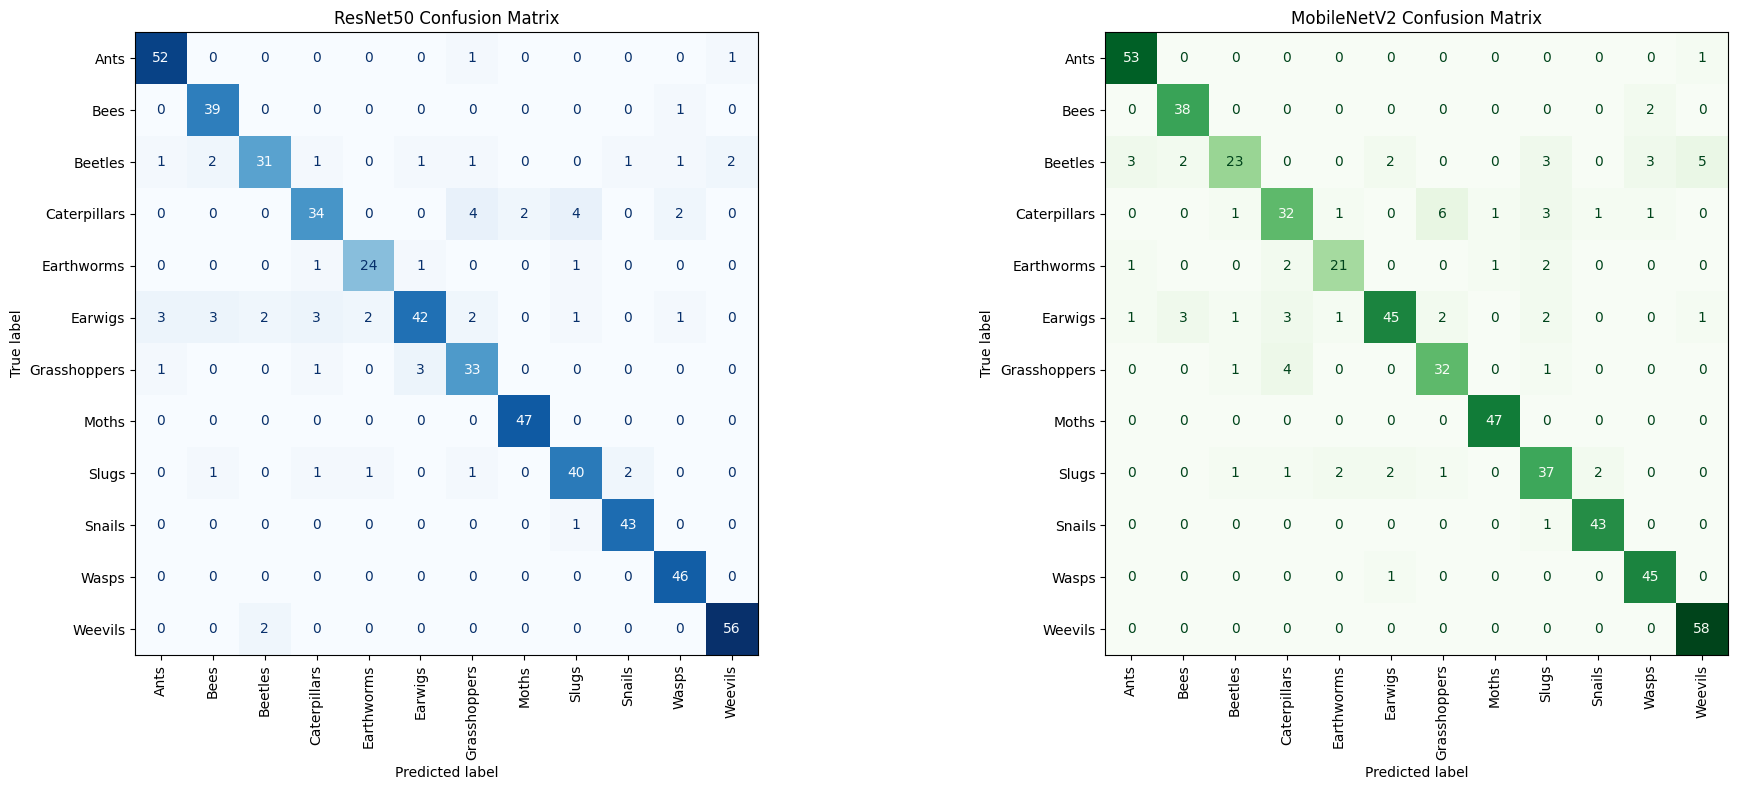

In [ ]:

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

ConfusionMatrixDisplay.from_predictions(
    resnet_y_true, resnet_y_pred,
    labels=np.arange(NUM_CLASSES),
    display_labels=class_names,
    xticks_rotation=90,
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("ResNet50 Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    mobile_y_true, mobile_y_pred,
    labels=np.arange(NUM_CLASSES),
    display_labels=class_names,
    xticks_rotation=90,
    cmap="Greens",
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("MobileNetV2 Confusion Matrix")

plt.tight_layout()
plt.show()


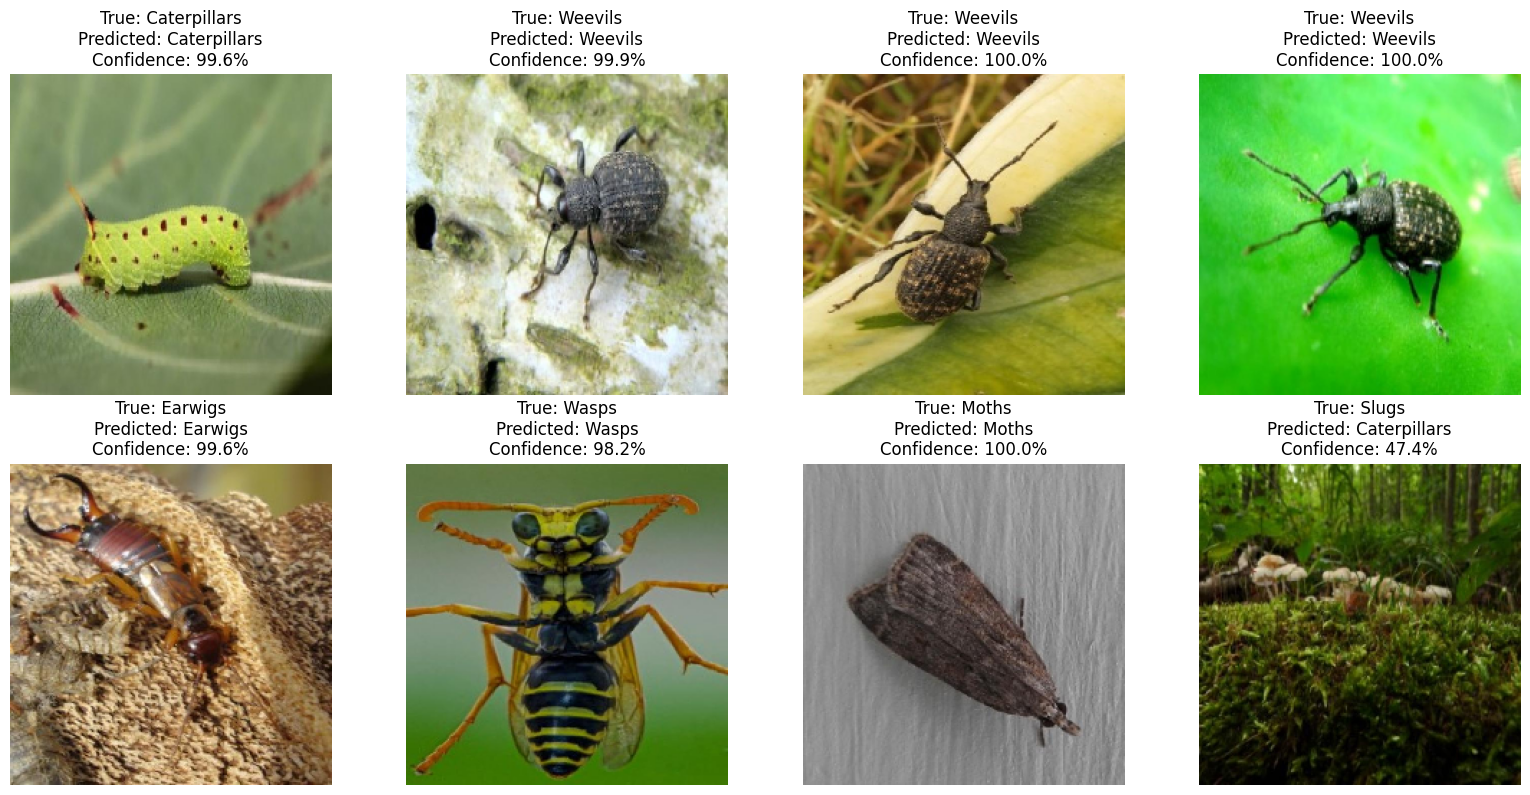

In [ ]:

def show_predictions(model, test_df, preprocess_function, n=8):
    sample = test_df.sample(
        n=min(n, len(test_df)), random_state=42
    ).reset_index(drop=True)

    plt.figure(figsize=(16, 8))

    for i, row in sample.iterrows():
        img = tf.keras.utils.load_img(
            row["filename"], target_size=IMG_SIZE
        )
        arr = tf.keras.utils.img_to_array(img)
        batch = preprocess_function(np.expand_dims(arr.copy(), axis=0))

        probs = model.predict(batch, verbose=0)[0]
        pred_id = int(np.argmax(probs))
        true_label = row["label"]
        predicted_label = class_names[pred_id]

        plt.subplot(2, 4, i + 1)
        plt.imshow(img)
        plt.title(
            f"True: {true_label}\nPredicted: {predicted_label}\n"
            f"Confidence: {probs[pred_id]:.1%}"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

show_predictions(
    resnet_model, test_df, resnet_preprocess
)


In [ ]:

required = [
    "resnet_model",
    "mobilenet_model",
    "resnet_preprocess",
    "mobilenet_preprocess",
    "test_df",
    "class_names"
]

missing = [name for name in required if name not in globals()]

if missing:
    print("Missing variables:", missing)
    print("The runtime may have reset. Restore or retrain the models first.")
else:
    print("Both models and required dataset variables are available.")
    print("ResNet50 parameters:", f"{resnet_model.count_params():,}")
    print("MobileNetV2 parameters:", f"{mobilenet_model.count_params():,}")
    print("Test images available:", len(test_df))


Both models and required dataset variables are available.
ResNet50 parameters: 23,612,300
MobileNetV2 parameters: 2,273,356
Test images available: 546


In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.utils import load_img, img_to_array

# Last convolutional feature layers
RESNET_LAYER = "conv5_block3_out"
MOBILE_LAYER = "out_relu"

print("ResNet50 Grad-CAM layer:",
      resnet_model.get_layer(RESNET_LAYER).name)
print("MobileNetV2 Grad-CAM layer:",
      mobilenet_model.get_layer(MOBILE_LAYER).name)


ResNet50 Grad-CAM layer: conv5_block3_out
MobileNetV2 Grad-CAM layer: out_relu


In [ ]:

def make_gradcam_heatmap(model, image_batch, layer_name, class_index=None):
    grad_model = Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(
            image_batch, training=False
        )

        if class_index is None:
            class_index = tf.argmax(
                predictions[0]
            )

        class_score = predictions[:, class_index]

    grads = tape.gradient(class_score, conv_outputs)

    if grads is None:
        raise ValueError(
            "Gradients unavailable for layer: " + layer_name
        )

    # Average gradients over spatial dimensions
    weights = tf.reduce_mean(grads, axis=(1, 2))

    conv_outputs = conv_outputs[0]
    weights = weights[0]

    heatmap = tf.reduce_sum(
        conv_outputs * weights[tf.newaxis, tf.newaxis, :],
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    return heatmap.numpy()

print("Grad-CAM function created successfully.")


Grad-CAM function created successfully.


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_182']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


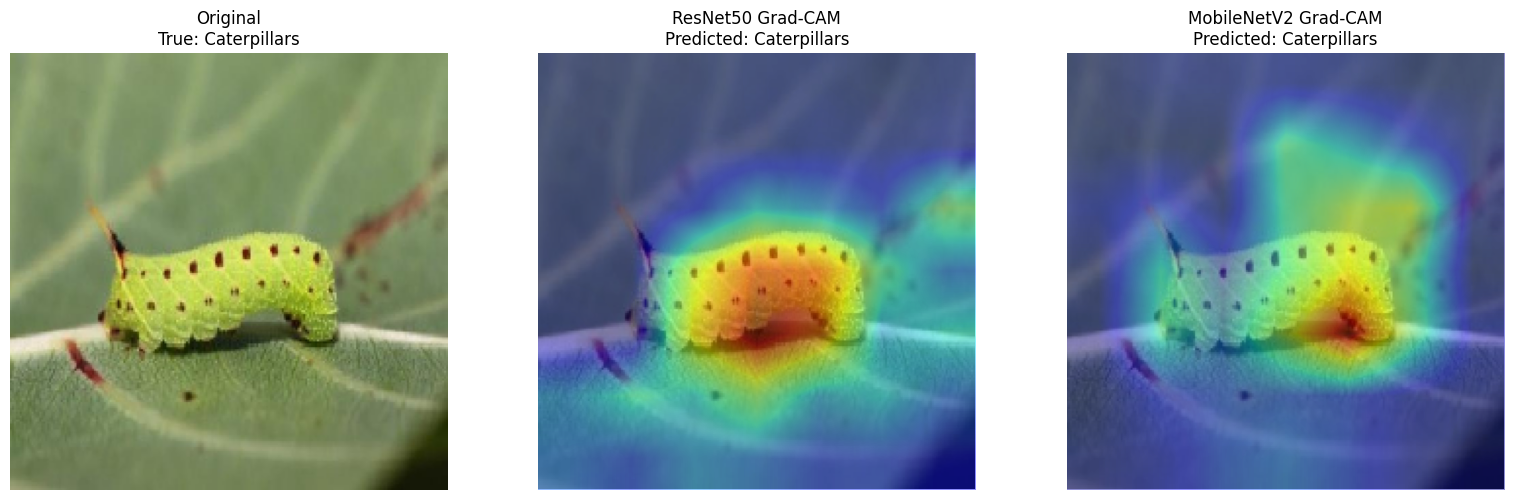

Grad-CAM figure saved to: /content/crop_pest_results/gradcam/gradcam_comparison.png
ResNet50 confidence: 99.62%
MobileNetV2 confidence: 68.59%


In [ ]:

os.makedirs("/content/crop_pest_results/gradcam", exist_ok=True)

# Choose a reproducible test image
sample_row = test_df.sample(
    n=1, random_state=42
).iloc[0]

image_path = sample_row["filename"]

original_img = load_img(
    image_path, target_size=(224, 224)
)
original_array = img_to_array(original_img)
image_batch = np.expand_dims(original_array.copy(), axis=0)

# Preprocess separately for each model
resnet_input = resnet_preprocess(image_batch.copy())
mobile_input = mobilenet_preprocess(image_batch.copy())

resnet_probs = resnet_model.predict(resnet_input, verbose=0)[0]
mobile_probs = mobilenet_model.predict(mobile_input, verbose=0)[0]

resnet_class = int(np.argmax(resnet_probs))
mobile_class = int(np.argmax(mobile_probs))

resnet_heatmap = make_gradcam_heatmap(
    resnet_model, resnet_input, RESNET_LAYER, resnet_class
)

mobile_heatmap = make_gradcam_heatmap(
    mobilenet_model, mobile_input, MOBILE_LAYER, mobile_class
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(original_img)
axes[0].set_title(f"Original\nTrue: {sample_row['label']}")
axes[0].axis("off")

axes[1].imshow(original_img)
axes[1].imshow(
    resnet_heatmap,
    cmap="jet",
    alpha=0.45,
    extent=(0, 224, 224, 0),
    interpolation="bilinear"
)
axes[1].set_title(
    f"ResNet50 Grad-CAM\nPredicted: {class_names[resnet_class]}"
)
axes[1].axis("off")

axes[2].imshow(original_img)
axes[2].imshow(
    mobile_heatmap,
    cmap="jet",
    alpha=0.45,
    extent=(0, 224, 224, 0),
    interpolation="bilinear"
)
axes[2].set_title(
    f"MobileNetV2 Grad-CAM\nPredicted: {class_names[mobile_class]}"
)
axes[2].axis("off")

plt.tight_layout()

gradcam_path = (
    "/content/crop_pest_results/gradcam/gradcam_comparison.png"
)
plt.savefig(gradcam_path, dpi=200, bbox_inches="tight")
plt.show()

print("Grad-CAM figure saved to:", gradcam_path)
print("ResNet50 confidence:", f"{resnet_probs[resnet_class]:.2%}")
print("MobileNetV2 confidence:", f"{mobile_probs[mobile_class]:.2%}")


In [ ]:

import os

RESULT_DIR = "/content/crop_pest_results"
os.makedirs(RESULT_DIR, exist_ok=True)

resnet_model.save(
    os.path.join(RESULT_DIR, "resnet50_crop_pest.keras")
)

mobilenet_model.save(
    os.path.join(RESULT_DIR, "mobilenetv2_crop_pest.keras")
)

print("Models saved successfully:")
print("1. resnet50_crop_pest.keras")
print("2. mobilenetv2_crop_pest.keras")


Models saved successfully:
1. resnet50_crop_pest.keras
2. mobilenetv2_crop_pest.keras


In [ ]:

import pandas as pd
import os

# Save evaluation metrics
if "results_df" in globals():
    results_df.to_csv(
        os.path.join(RESULT_DIR, "model_comparison_metrics.csv"),
        index=False
    )
elif "resnet_results" in globals() and "mobile_results" in globals():
    results_df = pd.DataFrame([resnet_results, mobile_results])
    results_df.to_csv(
        os.path.join(RESULT_DIR, "model_comparison_metrics.csv"),
        index=False
    )
else:
    print("Metrics table not found. Run Step 9 and Step 10 first.")

# Save classification reports
for model_name, y_true, y_pred in [
    ("resnet50", resnet_y_true, resnet_y_pred),
    ("mobilenetv2", mobile_y_true, mobile_y_pred)
]:
    report = classification_report(
        y_true,
        y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(report).transpose().to_csv(
        os.path.join(RESULT_DIR, f"{model_name}_classification_report.csv")
    )

# Save training histories
for name, history in [
    ("resnet50", resnet_history),
    ("mobilenetv2", mobilenet_history)
]:
    pd.DataFrame(history.history).to_csv(
        os.path.join(RESULT_DIR, f"{name}_training_history.csv"),
        index_label="epoch"
    )

print("\nAvailable results saved in:", RESULT_DIR)
print("Files:", sorted(os.listdir(RESULT_DIR)))



Available results saved in: /content/crop_pest_results
Files: ['gradcam', 'mobilenetv2_classification_report.csv', 'mobilenetv2_crop_pest.keras', 'mobilenetv2_training_history.csv', 'model_comparison_metrics.csv', 'resnet50_classification_report.csv', 'resnet50_crop_pest.keras', 'resnet50_training_history.csv']


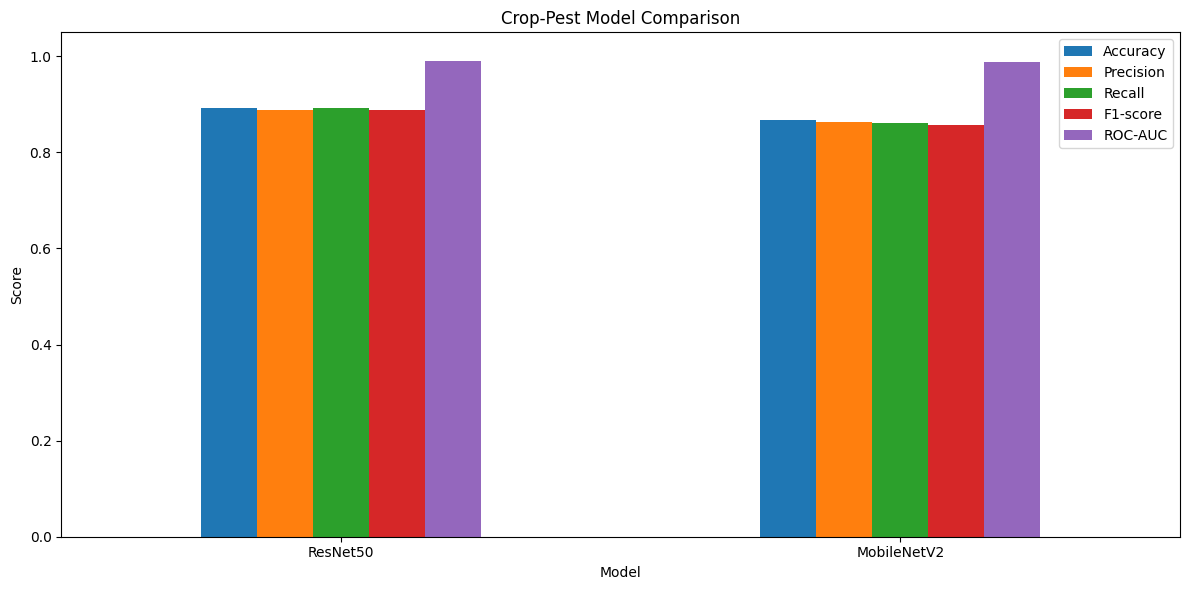

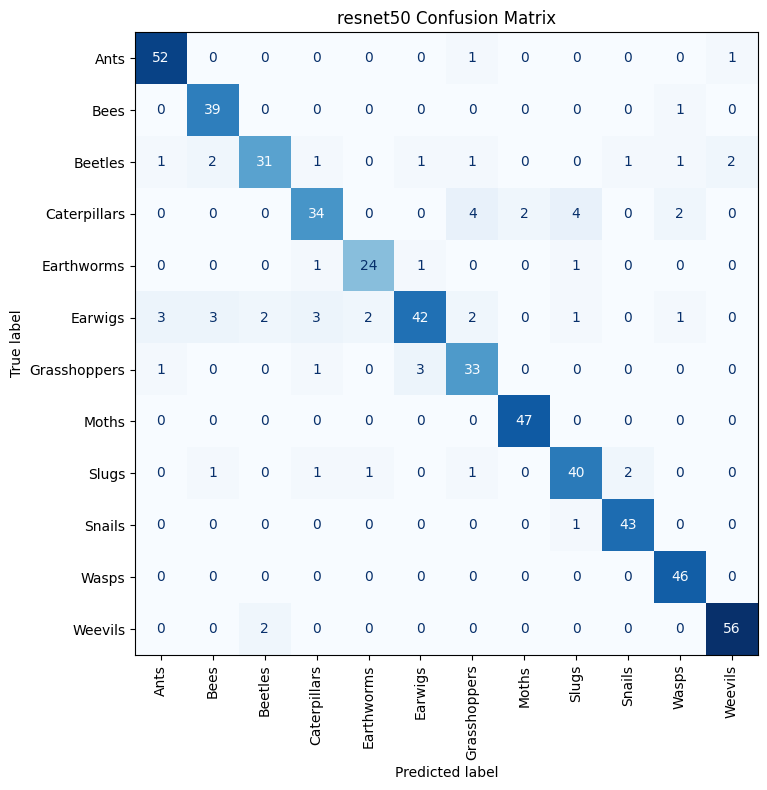

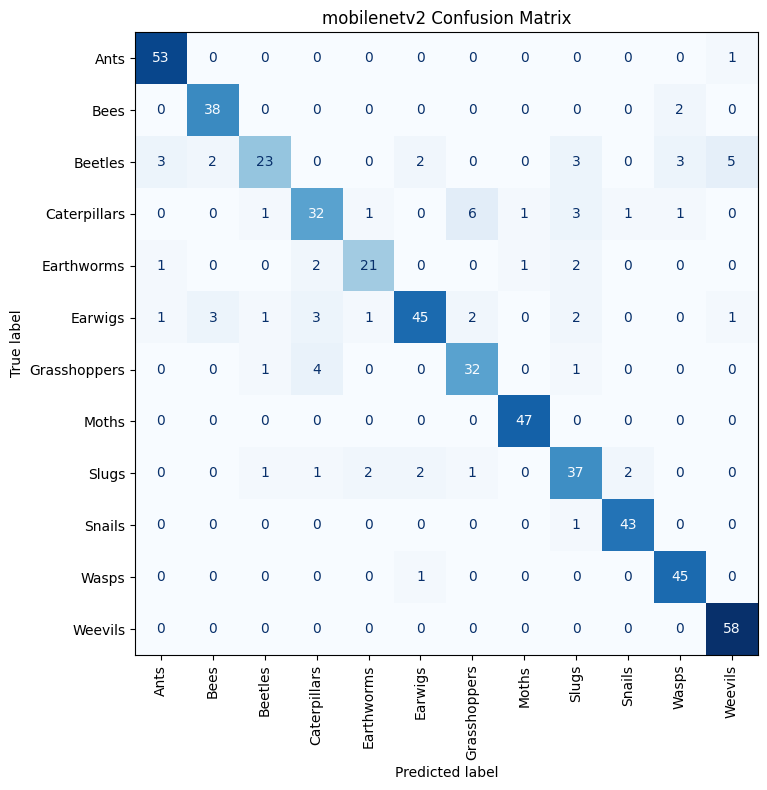

Comparison graph and confusion matrices saved.


In [ ]:

from sklearn.metrics import ConfusionMatrixDisplay

# Save the model comparison bar chart
metric_columns = [
    "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"
]

results_df.set_index("Model")[metric_columns].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1.05)
)
plt.title("Crop-Pest Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    os.path.join(RESULT_DIR, "model_comparison.png"),
    dpi=200, bbox_inches="tight"
)
plt.show()

# Save confusion matrices
for name, y_true, y_pred in [
    ("resnet50", resnet_y_true, resnet_y_pred),
    ("mobilenetv2", mobile_y_true, mobile_y_pred)
]:
    fig, ax = plt.subplots(figsize=(10, 8))

    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred,
        labels=np.arange(len(class_names)),
        display_labels=class_names,
        xticks_rotation=90,
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(f"{name} Confusion Matrix")
    plt.tight_layout()
    plt.savefig(
        os.path.join(RESULT_DIR, f"{name}_confusion_matrix.png"),
        dpi=200, bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

print("Comparison graph and confusion matrices saved.")
